In [9]:
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
from datetime import timedelta
import numpy as np

# 1. CARGA Y FILTRADO
# ---------------------------------------------------------
# Asumimos que cargas todos los años en un solo dataframe 'df'
# df = pd.read_csv("transacciones_extraidas_todos_los_años.csv")
# Para el ejemplo usamos tu archivo t.csv
try:
    df = pd.read_csv('../2022-2025.csv')
except:
    df = pd.read_csv('../2022-2025.csv', sep=',', engine='python')

# Filtrar solo 'Purchase' (P) limpiando espacios en blanco
df['Tx_Type'] = df['Tx_Type'].astype(str).str.strip().str.upper()
df_strat = df[df['Tx_Type'] == 'P'].copy()

# 2. DEFINICIÓN DE FECHAS (ESTRATEGIA 90 DÍAS)
# ---------------------------------------------------------
# Convertimos Notif_Date. Usamos errors='coerce' para saltar formatos ilegibles
# dayfirst=False asume formato americano (Mes/Dia/Año) común en estos reportes,
# pero pandas intentará inferir si es ambiguo.
df_strat['Buy_Date'] = pd.to_datetime(df_strat['Notif_Date'], errors='coerce', dayfirst=False)

# Eliminamos filas donde no se pudo entender la fecha
df_strat = df_strat.dropna(subset=['Buy_Date'])

# Limpiamos filas sin Ticker (Acronym) ya que no podemos comprar sin ticker
df_strat = df_strat.dropna(subset=['Acronym'])
df_strat['Acronym'] = df_strat['Acronym'].str.strip().str.upper()

df_strat = df_strat[df_strat["Filing Status"] == 'new']

print(f"Operaciones a analizar: {len(df_strat)}")
df_strat[['Buy_Date', 'Acronym', 'Asset']].head()

Operaciones a analizar: 6730


,Buy_Date,Acronym,Asset
7,2022-01-03,AM,Antero Midstream Corporation (AM) [ST]
10,2022-01-03,ENLC,"Enlink Midstream, llC Common units representin..."
12,2021-11-24,NGL,NGl ENERGY PARTNERS lP Common units representi...
14,2022-01-03,PBFX,PbF logistics lP Common units representing lim...
15,2022-01-03,PAA,"Plains All American Pipeline, l.P. - Common un..."


In [10]:
import time
import pandas as pd
import yfinance as yf
import numpy as np

# ==============================================================================
# BLOQUE 1: PREPARACIÓN DE LA LISTA DE TICKERS
# ==============================================================================
tickers = df_strat['Acronym'].dropna().unique().tolist()
print(f"Total de tickers únicos a descargar: {len(tickers)}")

# ==============================================================================
# BLOQUE 2: CONFIGURACIÓN DE LA DESCARGA POR TANDAS (BATCHING)
# ==============================================================================
BATCH_SIZE = 40
PAUSE_SECONDS = 1.5

def chunked_list(lst, n):
    for i in range(0, len(lst), n):
        yield lst[i:i + n]

data_frames_list = []

# ==============================================================================
# BLOQUE 3: EL BUCLE DE DESCARGA
# ==============================================================================
print(f"Iniciando descarga en tandas de {BATCH_SIZE}...")
chunks = list(chunked_list(tickers, BATCH_SIZE))

for i, batch in enumerate(chunks):
    print(f"Descargando lote {i+1}/{len(chunks)}...", end=" ")
    try:
        # Descargamos desde 2024 para cubrir bien el 2025
        batch_data = yf.download(batch, start="2021-01-01", progress=False, auto_adjust=True)
        
        if len(batch) > 1:
            close_prices = batch_data['Close']
        else:
            close_prices = pd.DataFrame({batch[0]: batch_data['Close']})
            
        data_frames_list.append(close_prices)
        print("OK.")
    except Exception as e:
        print(f"Error: {e}")
    time.sleep(PAUSE_SECONDS)

# ==============================================================================
# BLOQUE 4: CONSOLIDACIÓN DE DATOS
# ==============================================================================
print("Unificando datos...")
if data_frames_list:
    hist_data = pd.concat(data_frames_list, axis=1)
    hist_data = hist_data.dropna(axis=1, how='all')
else:
    hist_data = pd.DataFrame()

print(f"Matriz de precios final: {hist_data.shape}")


Total de tickers únicos a descargar: 1355
Iniciando descarga en tandas de 40...
Descargando lote 1/34... 

$IS: possibly delisted; no timezone found
$ITCI: possibly delisted; no timezone found
$TWTR: possibly delisted; no timezone found
$ENLC: possibly delisted; no timezone found
$ANTM: possibly delisted; no timezone found
$PBFX: possibly delisted; no timezone found

6 Failed downloads:
['IS', 'ITCI', 'TWTR', 'ENLC', 'ANTM', 'PBFX']: possibly delisted; no timezone found


OK.


$TELL: possibly delisted; no timezone found


Descargando lote 2/34... 

$SRLP: possibly delisted; no timezone found
$PXD: possibly delisted; no timezone found
$BRK: possibly delisted; no price data found  (1d 2021-01-01 -> 2026-03-08)
$WRK: possibly delisted; no timezone found

5 Failed downloads:
['TELL', 'SRLP', 'PXD', 'WRK']: possibly delisted; no timezone found
['BRK']: possibly delisted; no price data found  (1d 2021-01-01 -> 2026-03-08)


... (65 outputs left out)

$BHLB: possibly delisted; no timezone found

1 Failed download:
['BHLB']: possibly delisted; no timezone found


OK.
Descargando lote 34/34... 

$XMEX: possibly delisted; no timezone found
$ICAPITAL: possibly delisted; no timezone found

2 Failed downloads:
['XMEX', 'ICAPITAL']: possibly delisted; no timezone found


OK.
Unificando datos...
Matriz de precios final: (1299, 1253)


In [13]:
df_strat['Buy_Date'] = pd.to_datetime(df_strat['Date'], errors='coerce', dayfirst=False)

# Eliminamos filas donde no se pudo entender la fecha
df_strat = df_strat.dropna(subset=['Buy_Date'])


# Definimos fecha de venta = Notif_Date + 60 días
df_strat['Sell_Date'] = df_strat['Buy_Date'] + timedelta(days=19)

# ==============================================================================
# BLOQUE 5: CÁLCULO DE PRECIOS (CREACIÓN DE COLUMNA Buy_Price)
# ==============================================================================

def get_price_robust(ticker, target_date, lookup_df, method='exact'):
    if ticker not in lookup_df.columns: return np.nan
    series = lookup_df[ticker].dropna()
    if series.empty: return np.nan
    try:
        if method == 'forward':
            idx = series.index.get_indexer([target_date], method='bfill')[0]
        elif method == 'nearest':
            idx = series.index.get_indexer([target_date], method='nearest')[0]
        else:
            idx = -1
        if idx != -1 and idx < len(series): return series.iloc[idx]
    except: return np.nan
    return np.nan

print("Calculando precios de entrada y salida...")
df_strat['Buy_Price'] = df_strat.apply(lambda row: get_price_robust(row['Acronym'], row['Buy_Date'], hist_data, 'forward'), axis=1)
df_strat['Sell_Price'] = df_strat.apply(lambda row: get_price_robust(row['Acronym'], row['Sell_Date'], hist_data, 'nearest'), axis=1)
df_strat['Return'] = (df_strat['Sell_Price'] - df_strat['Buy_Price']) / df_strat['Buy_Price']
df_strat['Return'] = df_strat['Return'].fillna(0.0)

# ==============================================================================
# PASO 2.5: DIAGNÓSTICO (AHORA SÍ FUNCIONARÁ)
# ==============================================================================
total_ops = len(df_strat)
# Ahora Buy_Price YA EXISTE
ops_con_precio = len(df_strat[df_strat['Buy_Price'] > 0])
ops_fallidas = total_ops - ops_con_precio

print(f"\n--- DIAGNÓSTICO 2025 ---")
print(f"Total Operaciones: {total_ops}")
print(f"Operaciones Válidas: {ops_con_precio}")
print(f"Fallidas: {ops_fallidas}")

# Preparar df_clean para la siguiente celda
df_clean = df_strat[df_strat['Buy_Price'] > 0].copy()

Calculando precios de entrada y salida...

--- DIAGNÓSTICO 2025 ---
Total Operaciones: 6679
Operaciones Válidas: 6356
Fallidas: 323


Descargando datos del S&P 500 (SPY) para la comparativa...
Simulando las mismas operaciones en el S&P 500...


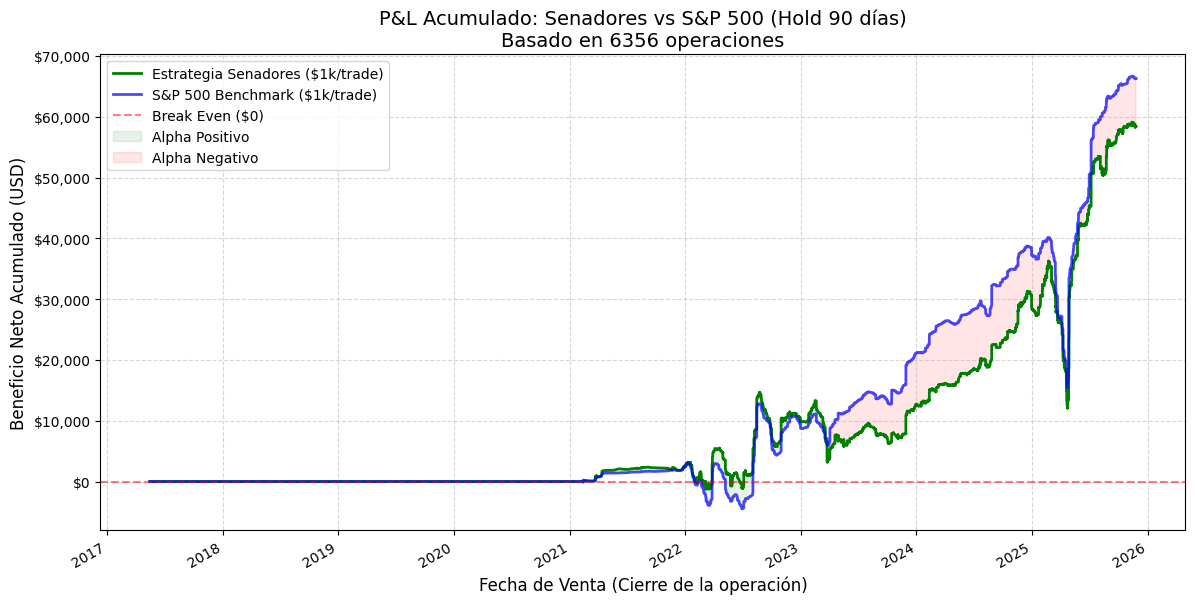


--- RESULTADOS COMPARATIVOS (Por cada $1,000 por operación) ---
Total Operaciones Cerradas: 6356
Capital total movilizado: $6,356,000.00

BENEFICIO SENADORES: $58,408.92
BENEFICIO S&P 500:   $66,258.42
-> Los senadores PERDIERON frente al mercado por: -$7,849.50.

Tasa de Acierto Senadores: 55.33%
Tasa de Acierto S&P 500:   66.27%
Retorno Promedio Senadores: 0.92%
Retorno Promedio S&P 500:   1.04%


In [14]:
import yfinance as yf
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np

# ==============================================================================
# PASO 3: GRAFICADO CORRECTO Y COMPARATIVA S&P 500 (BENCHMARK)
# ==============================================================================

if len(df_clean) > 0:
    print("Descargando datos del S&P 500 (SPY) para la comparativa...")
    
    # 1. DESCARGAR BENCHMARK (SPY)
    try:
        spy_data = yf.download('SPY', start="2021-01-01", progress=False, auto_adjust=True)
        # yfinance a veces devuelve multi-index, aseguramos coger la serie de Close
        if isinstance(spy_data.columns, pd.MultiIndex):
            spy_series = spy_data['Close']['SPY'].dropna()
        else:
            spy_series = spy_data['Close'].dropna()
    except Exception as e:
        print(f"Error descargando SPY: {e}")
        spy_series = pd.Series(dtype=float)

    # 2. FUNCIÓN PARA BUSCAR PRECIO SPY
    def get_spy_price(target_date, method='forward'):
        if spy_series.empty: return np.nan
        try:
            if method == 'forward':
                idx = spy_series.index.get_indexer([target_date], method='bfill')[0]
            else:
                idx = spy_series.index.get_indexer([target_date], method='nearest')[0]
            if idx != -1 and idx < len(spy_series):
                return spy_series.iloc[idx]
        except: return np.nan
        return np.nan

    # 3. CÁLCULO DE RETORNOS DEL MERCADO PARA CADA OPERACIÓN
    print("Simulando las mismas operaciones en el S&P 500...")
    df_clean['Buy_Price_SPY'] = df_clean['Buy_Date'].apply(lambda x: get_spy_price(x, 'forward'))
    df_clean['Sell_Price_SPY'] = df_clean['Sell_Date'].apply(lambda x: get_spy_price(x, 'nearest'))
    
    df_clean['Return_SPY'] = (df_clean['Sell_Price_SPY'] - df_clean['Buy_Price_SPY']) / df_clean['Buy_Price_SPY']
    df_clean['Return_SPY'] = df_clean['Return_SPY'].fillna(0.0)

    # 4. ORDEN CRONOLÓGICO REAL
    df_clean = df_clean.sort_values('Sell_Date')

    # 5. LÓGICA DE INVERSIÓN (TAMAÑO FIJO: $1,000 por señal)
    INVERSION_POR_TRADE = 1000
    
    # PnL Senadores
    df_clean['PnL_USD'] = df_clean['Return'] * INVERSION_POR_TRADE
    df_clean['Beneficio_Acumulado'] = df_clean['PnL_USD'].cumsum()
    
    # PnL S&P 500
    df_clean['PnL_SPY_USD'] = df_clean['Return_SPY'] * INVERSION_POR_TRADE
    df_clean['Beneficio_Acumulado_SPY'] = df_clean['PnL_SPY_USD'].cumsum()

    # 6. GRAFICAR
    plt.figure(figsize=(14, 7))
    
    # Línea de los Senadores
    plt.plot(df_clean['Sell_Date'], df_clean['Beneficio_Acumulado'], 
             label='Estrategia Senadores ($1k/trade)', color='green', linewidth=2)
    
    # Línea del S&P 500
    plt.plot(df_clean['Sell_Date'], df_clean['Beneficio_Acumulado_SPY'], 
             label='S&P 500 Benchmark ($1k/trade)', color='blue', linewidth=2, alpha=0.7)
    
    # Línea base de 0 dólares
    plt.axhline(y=0, color='r', linestyle='--', alpha=0.5, label='Break Even ($0)')

    # Sombrear la diferencia (Alpha)
    plt.fill_between(df_clean['Sell_Date'], df_clean['Beneficio_Acumulado'], df_clean['Beneficio_Acumulado_SPY'], 
                     where=(df_clean['Beneficio_Acumulado'] > df_clean['Beneficio_Acumulado_SPY']), 
                     interpolate=True, color='green', alpha=0.1, label='Alpha Positivo')
                     
    plt.fill_between(df_clean['Sell_Date'], df_clean['Beneficio_Acumulado'], df_clean['Beneficio_Acumulado_SPY'], 
                     where=(df_clean['Beneficio_Acumulado'] <= df_clean['Beneficio_Acumulado_SPY']), 
                     interpolate=True, color='red', alpha=0.1, label='Alpha Negativo')

    plt.title(f'P&L Acumulado: Senadores vs S&P 500 (Hold 90 días)\nBasado en {len(df_clean)} operaciones', fontsize=14)
    plt.xlabel('Fecha de Venta (Cierre de la operación)', fontsize=12)
    plt.ylabel('Beneficio Neto Acumulado (USD)', fontsize=12)
    
    # Formatear eje Y como dólares
    fmt = '${x:,.0f}'
    tick = mtick.StrMethodFormatter(fmt)
    plt.gca().yaxis.set_major_formatter(tick)
    
    plt.grid(True, which='both', linestyle='--', alpha=0.5)
    plt.legend()
    plt.gcf().autofmt_xdate()
    plt.show()

    # 7. ESTADÍSTICAS COMPARATIVAS
    print("\n--- RESULTADOS COMPARATIVOS (Por cada $1,000 por operación) ---")
    ganancia_senadores = df_clean['Beneficio_Acumulado'].iloc[-1]
    ganancia_spy = df_clean['Beneficio_Acumulado_SPY'].iloc[-1]
    alpha = ganancia_senadores - ganancia_spy
    
    capital_necesario = len(df_clean) * INVERSION_POR_TRADE
    win_rate_senadores = len(df_clean[df_clean['Return'] > 0]) / len(df_clean) * 100
    win_rate_spy = len(df_clean[df_clean['Return_SPY'] > 0]) / len(df_clean) * 100
    
    print(f"Total Operaciones Cerradas: {len(df_clean)}")
    print(f"Capital total movilizado: ${capital_necesario:,.2f}\n")
    
    print(f"BENEFICIO SENADORES: ${ganancia_senadores:,.2f}")
    print(f"BENEFICIO S&P 500:   ${ganancia_spy:,.2f}")
    
    if alpha > 0:
        print(f"-> Los senadores BATIERON al mercado por: +${alpha:,.2f} de ganancia extra.")
    else:
        print(f"-> Los senadores PERDIERON frente al mercado por: -${abs(alpha):,.2f}.")
        
    print(f"\nTasa de Acierto Senadores: {win_rate_senadores:.2f}%")
    print(f"Tasa de Acierto S&P 500:   {win_rate_spy:.2f}%")
    print(f"Retorno Promedio Senadores: {(df_clean['Return'].mean() * 100):.2f}%")
    print(f"Retorno Promedio S&P 500:   {(df_clean['Return_SPY'].mean() * 100):.2f}%")

else:
    print("No hay suficientes datos válidos para graficar.")

<>:63: SyntaxWarning: invalid escape sequence '\m'
<>:63: SyntaxWarning: invalid escape sequence '\m'
C:\Users\victo\AppData\Local\Temp\ipykernel_5784\2425361818.py:63: SyntaxWarning: invalid escape sequence '\m'
  Line2D([0], [0], marker='$\mathregular{n=X}$', color='w', label='Total de Operaciones', markerfacecolor='black', markersize=10)


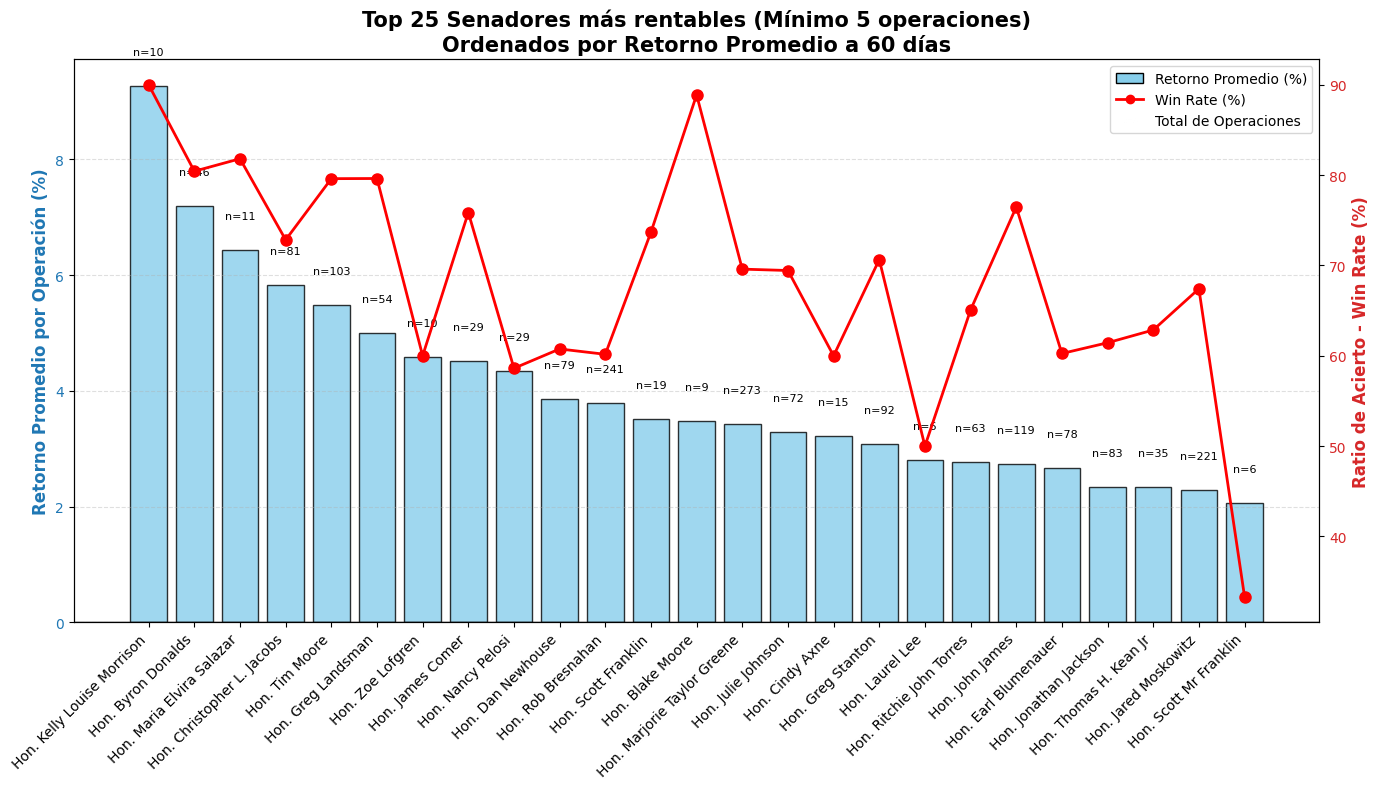


--- TOP 10 SENADORES MÁS RENTABLES ---
                      Name  Total_Operaciones  Win_Rate  Retorno_Promedio
Hon. Kelly Louise Morrison                 10 90.000000          9.265009
        Hon. Byron Donalds                 46 80.434783          7.187670
 Hon. Maria Elvira Salazar                 11 81.818182          6.432475
Hon. Christopher L. Jacobs                 81 72.839506          5.820920
            Hon. Tim Moore                103 79.611650          5.475624
        Hon. Greg Landsman                 54 79.629630          5.003151
          Hon. Zoe Lofgren                 10 60.000000          4.591074
          Hon. James Comer                 29 75.862069          4.521065
         Hon. Nancy Pelosi                 29 58.620690          4.334776
         Hon. Dan Newhouse                 79 60.759494          3.859749

--- LOS 5 SENADORES MENOS RENTABLES (Que más pierden) ---
                  Name  Total_Operaciones  Win_Rate  Retorno_Promedio
  Hon. Bruce West

In [44]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# ==============================================================================
# PASO 4: ANÁLISIS POR SENADOR (RANKING)
# ==============================================================================

# 1. Agrupar datos por Político
ranking = df_clean.groupby('Name').agg(
    Total_Operaciones=('Return', 'count'),
    Win_Rate=('Return', lambda x: (x > 0).mean() * 100),
    Retorno_Promedio=('Return', lambda x: x.mean() * 100)
).reset_index()

# 2. Filtrar ruido: Exigir un mínimo de operaciones para que la estadística sea fiable
MIN_OPERACIONES = 5  # Puedes cambiar este número
ranking = ranking[ranking['Total_Operaciones'] >= MIN_OPERACIONES]

# 3. Ordenar por el que tiene mayor retorno promedio
ranking = ranking.sort_values('Retorno_Promedio', ascending=False)

# Si hay muchísimos políticos, nos quedamos con el TOP 25 para que la gráfica sea legible
TOP_N = 25
ranking_top = ranking.head(TOP_N)

# 4. PLOTEAR: Gráfico combinado (Barras + Línea)
fig, ax1 = plt.subplots(figsize=(14, 8))

# Eje Principal (Barras azules): Retorno Promedio
bars = ax1.bar(ranking_top['Name'], ranking_top['Retorno_Promedio'], color='skyblue', edgecolor='black', alpha=0.8)
ax1.set_ylabel('Retorno Promedio por Operación (%)', color='tab:blue', fontsize=12, fontweight='bold')
ax1.tick_params(axis='y', labelcolor='tab:blue')
ax1.set_xticks(range(len(ranking_top['Name'])))
ax1.set_xticklabels(ranking_top['Name'], rotation=45, ha='right', fontsize=10)
ax1.grid(axis='y', linestyle='--', alpha=0.4)

# Añadir el número de operaciones encima de cada barra
for bar, total in zip(bars, ranking_top['Total_Operaciones']):
    yval = bar.get_height()
    # Si el retorno es negativo, ponemos el texto debajo
    offset = 0.5 if yval >= 0 else -1.5
    ax1.text(bar.get_x() + bar.get_width()/2, yval + offset, f'n={total}', ha='center', va='bottom', fontsize=8, color='black')

# Eje Secundario (Línea roja): Win Rate
ax2 = ax1.twinx()
line = ax2.plot(ranking_top['Name'], ranking_top['Win_Rate'], color='red', marker='o', linestyle='-', linewidth=2, markersize=8)
ax2.set_ylabel('Ratio de Acierto - Win Rate (%)', color='tab:red', fontsize=12, fontweight='bold')
ax2.tick_params(axis='y', labelcolor='tab:red')

# Línea base en 0% para el retorno
ax1.axhline(0, color='black', linewidth=1)

# Títulos y leyenda
plt.title(f'Top {len(ranking_top)} Senadores más rentables (Mínimo {MIN_OPERACIONES} operaciones)\nOrdenados por Retorno Promedio a 60 días', fontsize=15, fontweight='bold')

# Crear una leyenda combinada
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
legend_elements = [
    Patch(facecolor='skyblue', edgecolor='black', label='Retorno Promedio (%)'),
    Line2D([0], [0], color='red', marker='o', lw=2, label='Win Rate (%)'),
    Line2D([0], [0], marker='$\mathregular{n=X}$', color='w', label='Total de Operaciones', markerfacecolor='black', markersize=10)
]
ax1.legend(handles=legend_elements, loc='upper right')

plt.tight_layout()
plt.show()

# 5. Imprimir la tabla de los 10 mejores y 5 peores
print("\n--- TOP 10 SENADORES MÁS RENTABLES ---")
print(ranking.head(10).to_string(index=False))

print("\n--- LOS 5 SENADORES MENOS RENTABLES (Que más pierden) ---")
print(ranking.tail(5).sort_values('Retorno_Promedio', ascending=True).to_string(index=False))

--- TOP SENADORES MÁS ACTIVOS (Mínimo 5 operaciones) ---
                           Name  Total_Operaciones Win_Rate Retorno_Promedio
           Hon. Josh Gottheimer                748   54.68%            0.74%
              Hon. Lisa McClain                543   51.20%            0.24%
             Hon. Kathy Manning                379   58.58%            0.89%
            Hon. Daniel Goldman                325   53.54%            1.12%
    Hon. Marjorie Taylor Greene                273   69.60%            3.42%
             Hon. Virginia Foxx                242   55.37%            0.03%
             Hon. Rob Bresnahan                241   60.17%            3.78%
           Hon. Jared Moskowitz                221   67.42%            2.29%
                Hon. Kevin Hern                212   59.91%            0.85%
             Hon. Valerie Hoyle                191   48.69%            0.14%
          Hon. Gilbert Cisneros                191   53.93%            1.13%
          Hon. Jeff

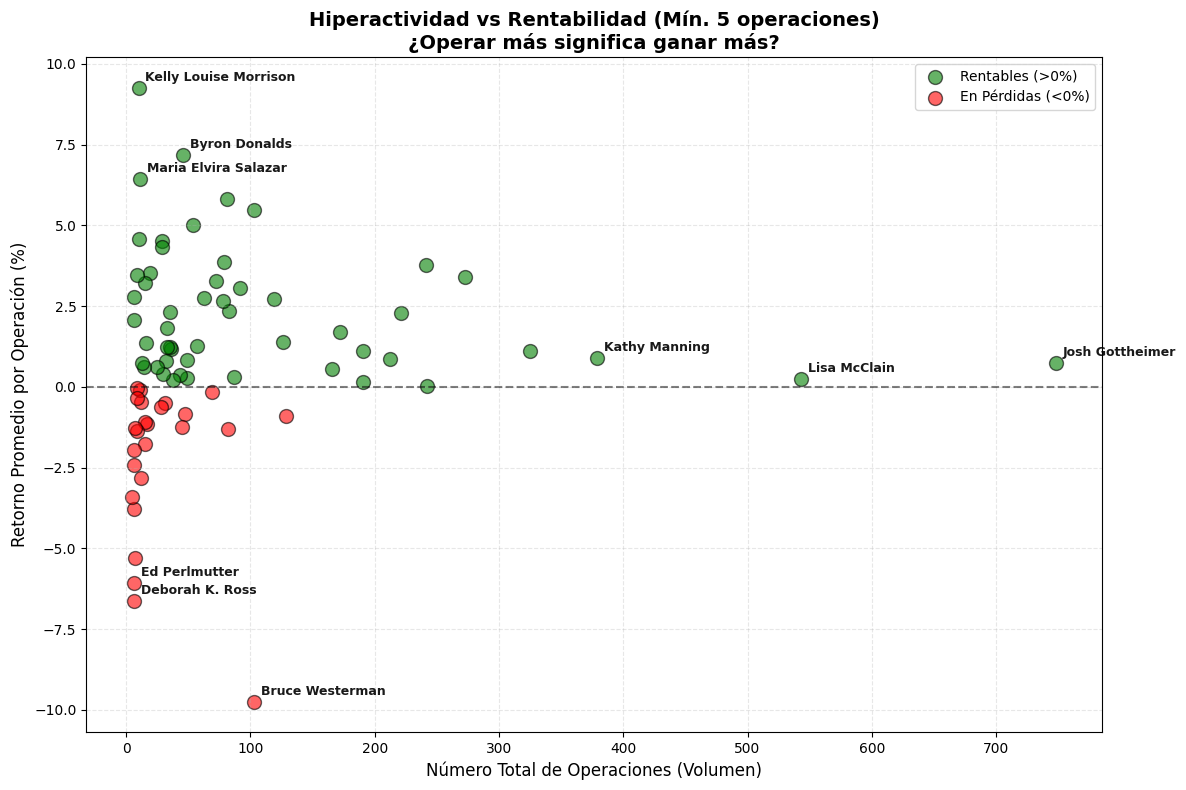

In [45]:
import pandas as pd
import matplotlib.pyplot as plt

# ==============================================================================
# PASO 5: ANÁLISIS POR VOLUMEN DE OPERACIONES (FILTRADO > 5 OPERACIONES)
# ==============================================================================

# 1. Agrupar datos por Político
actividad_senadores = df_clean.groupby('Name').agg(
    Total_Operaciones=('Return', 'count'),
    Win_Rate=('Return', lambda x: (x > 0).mean() * 100),
    Retorno_Promedio=('Return', lambda x: x.mean() * 100)
).reset_index()

# 2. APLICAR FILTRO: Solo senadores con 5 o más operaciones
MIN_OPERACIONES = 5
actividad_senadores = actividad_senadores[actividad_senadores['Total_Operaciones'] >= MIN_OPERACIONES]

# 3. Ordenar por Total de Operaciones (de mayor a menor)
actividad_senadores = actividad_senadores.sort_values('Total_Operaciones', ascending=False)

# 4. Mostrar la tabla de los 20 más activos en texto
print(f"--- TOP SENADORES MÁS ACTIVOS (Mínimo {MIN_OPERACIONES} operaciones) ---")
tabla_formateada = actividad_senadores.head(20).copy()
tabla_formateada['Win_Rate'] = tabla_formateada['Win_Rate'].map('{:.2f}%'.format)
tabla_formateada['Retorno_Promedio'] = tabla_formateada['Retorno_Promedio'].map('{:.2f}%'.format)
print(tabla_formateada.to_string(index=False))

# ==============================================================================
# 5. PLOTEAR: Volumen vs Retorno (Scatter Plot)
# ==============================================================================
plt.figure(figsize=(12, 8))

# Separar en ganadores y perdedores
ganadores = actividad_senadores[actividad_senadores['Retorno_Promedio'] >= 0]
perdedores = actividad_senadores[actividad_senadores['Retorno_Promedio'] < 0]

# Dibujar puntos
plt.scatter(ganadores['Total_Operaciones'], ganadores['Retorno_Promedio'], 
            color='green', alpha=0.6, s=100, edgecolor='black', label='Rentables (>0%)')
plt.scatter(perdedores['Total_Operaciones'], perdedores['Retorno_Promedio'], 
            color='red', alpha=0.6, s=100, edgecolor='black', label='En Pérdidas (<0%)')

# Línea base (0% de retorno)
plt.axhline(0, color='black', linestyle='--', alpha=0.5)

# Identificar a los extremos para ponerles el nombre en la gráfica
# Como hemos filtrado, cogemos a los 3 que más operan, y a los 3 que más ganan/pierden
extremos = pd.concat([
    actividad_senadores.nlargest(3, 'Total_Operaciones'), 
    actividad_senadores.nlargest(3, 'Retorno_Promedio'),
    actividad_senadores.nsmallest(3, 'Retorno_Promedio')
]).drop_duplicates()

for _, row in extremos.iterrows():
    # Limpiamos el texto 'Hon.' si existe para que no ocupe tanto
    nombre_limpio = row['Name'].replace('Hon. ', '').replace('Mr. ', '')
    plt.annotate(
        nombre_limpio, 
        (row['Total_Operaciones'], row['Retorno_Promedio']),
        xytext=(5, 5), textcoords='offset points', fontsize=9, alpha=0.9, weight='bold'
    )

plt.title(f'Hiperactividad vs Rentabilidad (Mín. {MIN_OPERACIONES} operaciones)\n¿Operar más significa ganar más?', fontsize=14, fontweight='bold')
plt.xlabel('Número Total de Operaciones (Volumen)', fontsize=12)
plt.ylabel('Retorno Promedio por Operación (%)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()

Calculando simulaciones de P&L para diferentes periodos de retención...
Esto puede tardar unos segundos...
¡Cálculos terminados! Generando gráficas...


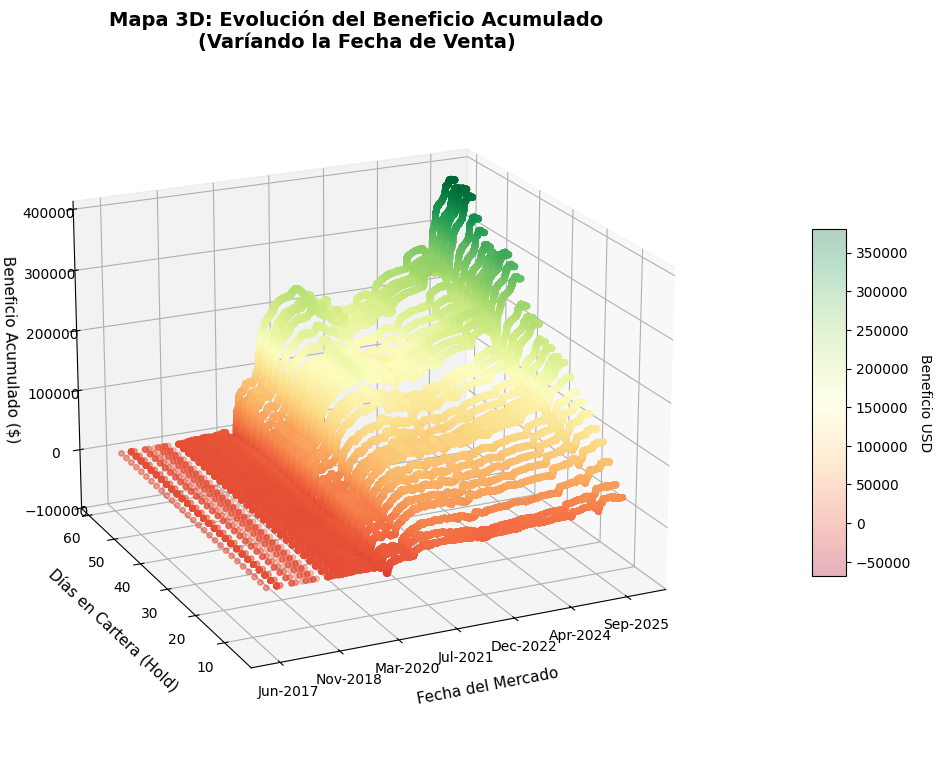

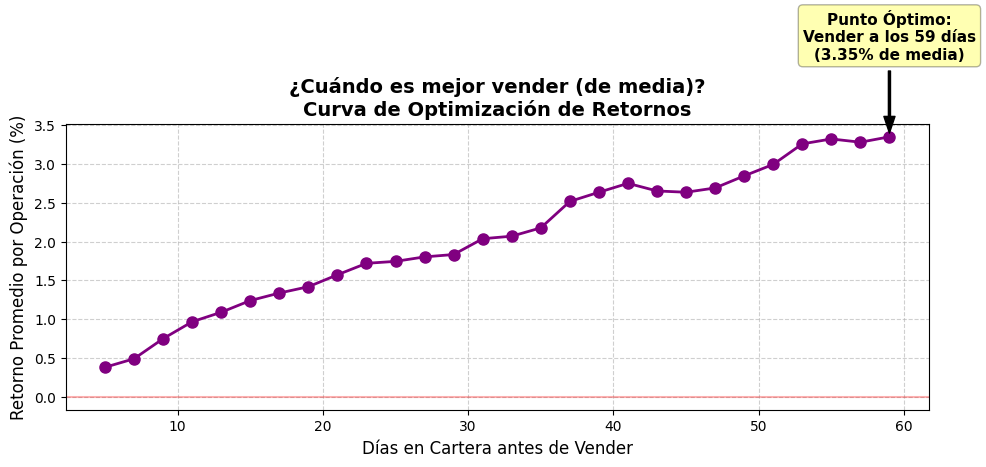

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from datetime import timedelta, date
from matplotlib.ticker import FuncFormatter

# ==============================================================================
# PASO 6: OPTIMIZACIÓN DE LA FECHA DE VENTA (ANÁLISIS 3D)
# ==============================================================================

# 1. Definir los periodos de retención a simular (De 10 a 120 días, de 10 en 10)
dias_evaluar = list(range(5, 60, 2))
resultados_3d = []
rendimiento_medio = []

print("Calculando simulaciones de P&L para diferentes periodos de retención...")
print("Esto puede tardar unos segundos...")

for dias in dias_evaluar:
    # Copiamos los datos base de compra
    df_sim = df_clean[['Buy_Date', 'Buy_Price', 'Acronym']].copy()
    
    # Calculamos la nueva fecha de venta
    df_sim['Sell_Date'] = df_sim['Buy_Date'] + timedelta(days=dias)
    
    # Buscamos el precio para esa nueva fecha
    # Usamos la función get_price_robust que ya creamos en el Paso 2
    df_sim['Sell_Price'] = df_sim.apply(
        lambda row: get_price_robust(row['Acronym'], row['Sell_Date'], hist_data, 'nearest'), axis=1
    )
    
    # Calcular Retorno
    df_sim['Return'] = (df_sim['Sell_Price'] - df_sim['Buy_Price']) / df_sim['Buy_Price']
    df_sim['Return'] = df_sim['Return'].fillna(0.0)
    
    # Guardar el retorno medio de este periodo para la gráfica 2D
    rendimiento_medio.append(df_sim['Return'].mean() * 100)
    
    # Calcular PnL Acumulado (Invirtiendo $1000)
    df_sim = df_sim.sort_values('Sell_Date')
    df_sim['PnL_USD'] = df_sim['Return'] * 1000
    df_sim['Beneficio_Acumulado'] = df_sim['PnL_USD'].cumsum()
    
    # Guardar puntos para el gráfico 3D
    for _, row in df_sim.iterrows():
        resultados_3d.append({
            'Fecha_Num': row['Sell_Date'].toordinal(), # Eje X numérico para el 3D
            'Dias_Hold': dias,                         # Eje Y
            'Beneficio': row['Beneficio_Acumulado']    # Eje Z
        })

df_3d = pd.DataFrame(resultados_3d)
print("¡Cálculos terminados! Generando gráficas...")

# ==============================================================================
# PLOT 1: GRÁFICO 3D (TIEMPO vs HOLDING vs BENEFICIO)
# ==============================================================================
fig = plt.figure(figsize=(14, 9))
ax = fig.add_subplot(111, projection='3d')

# Usamos un scatter 3D con mapa de calor (Verde = Mucho beneficio, Rojo = Poco/Pérdidas)
scatter = ax.scatter(df_3d['Fecha_Num'], df_3d['Dias_Hold'], df_3d['Beneficio'], 
                     c=df_3d['Beneficio'], cmap='RdYlGn', alpha=0.3, s=15)

# Convertir los números del Eje X de vuelta a Fechas legibles
def format_date(x, pos=None):
    try:
        return date.fromordinal(int(x)).strftime('%b-%Y')
    except:
        return ""

ax.xaxis.set_major_formatter(FuncFormatter(format_date))

ax.set_title('Mapa 3D: Evolución del Beneficio Acumulado\n(Varíando la Fecha de Venta)', fontsize=14, fontweight='bold')
ax.set_xlabel('Fecha del Mercado', fontsize=11, labelpad=10)
ax.set_ylabel('Días en Cartera (Hold)', fontsize=11, labelpad=10)
ax.set_zlabel('Beneficio Acumulado ($)', fontsize=11, labelpad=10)

# Añadir barra de color
cbar = fig.colorbar(scatter, ax=ax, shrink=0.5, aspect=10, pad=0.1)
cbar.set_label('Beneficio USD', rotation=270, labelpad=15)

# Rotación inicial recomendada
ax.view_init(elev=20, azim=-115)
plt.show()

# ==============================================================================
# PLOT 2: CURVA DE OPTIMIZACIÓN (El "Sweet Spot")
# ==============================================================================
plt.figure(figsize=(10, 5))
plt.plot(dias_evaluar, rendimiento_medio, marker='o', color='purple', linewidth=2, markersize=8)

plt.title('¿Cuándo es mejor vender (de media)?\nCurva de Optimización de Retornos', fontsize=14, fontweight='bold')
plt.xlabel('Días en Cartera antes de Vender', fontsize=12)
plt.ylabel('Retorno Promedio por Operación (%)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)

# Encontrar y destacar el punto máximo automáticamente
max_idx = np.argmax(rendimiento_medio)
mejor_dia = dias_evaluar[max_idx]
mejor_retorno = rendimiento_medio[max_idx]

plt.annotate(f'Punto Óptimo:\nVender a los {mejor_dia} días\n({mejor_retorno:.2f}% de media)', 
             xy=(mejor_dia, mejor_retorno), xytext=(mejor_dia, mejor_retorno + max(1, mejor_retorno*0.1)),
             arrowprops=dict(facecolor='black', shrink=0.05, width=1.5, headwidth=8),
             fontsize=11, fontweight='bold', ha='center', bbox=dict(boxstyle="round,pad=0.3", fc="yellow", alpha=0.3))

plt.axhline(0, color='red', linestyle='-', alpha=0.3)
plt.tight_layout()
plt.show()

Calculando simulaciones comparativas...
Buscando el punto de máxima ventaja contra el S&P 500...
¡Cálculos terminados! Generando gráfica...


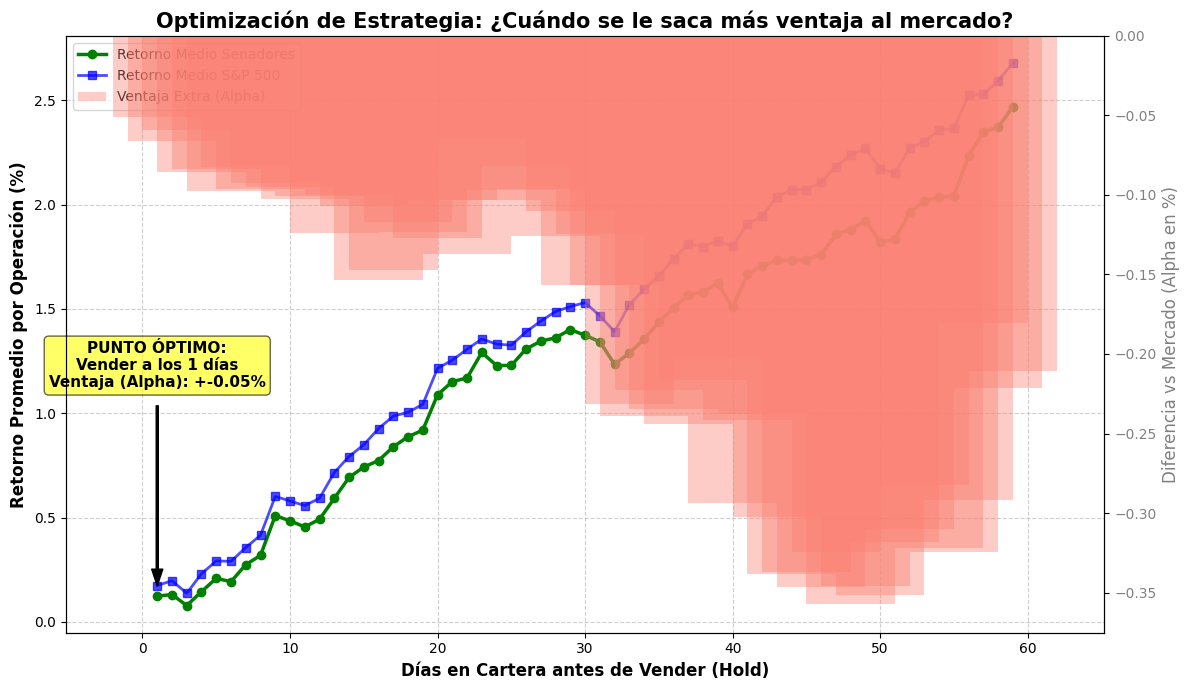

In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from datetime import timedelta

# ==============================================================================
# PASO 6: OPTIMIZACIÓN DE VENTA (SENADORES VS S&P 500)
# ==============================================================================

# Definir los periodos de retención a simular (De 10 a 120 días)
dias_evaluar = list(range(1, 60, 1))

rendimiento_senadores = []
rendimiento_spy = []
alpha_diferencia = []

print("Calculando simulaciones comparativas...")
print("Buscando el punto de máxima ventaja contra el S&P 500...")

for dias in dias_evaluar:
    # 1. Copiamos datos base
    df_sim = df_clean[['Buy_Date', 'Buy_Price', 'Acronym']].copy()
    df_sim['Sell_Date'] = df_sim['Buy_Date'] + timedelta(days=dias)
    
    # 2. Precio y Retorno Senadores
    df_sim['Sell_Price'] = df_sim.apply(
        lambda row: get_price_robust(row['Acronym'], row['Sell_Date'], hist_data, 'nearest'), axis=1
    )
    df_sim['Return'] = (df_sim['Sell_Price'] - df_sim['Buy_Price']) / df_sim['Buy_Price']
    df_sim['Return'] = df_sim['Return'].fillna(0.0)
    
    # 3. Precio y Retorno SPY (Benchmark)
    df_sim['Buy_Price_SPY'] = df_sim['Buy_Date'].apply(lambda x: get_spy_price(x, 'forward'))
    df_sim['Sell_Price_SPY'] = df_sim['Sell_Date'].apply(lambda x: get_spy_price(x, 'nearest'))
    df_sim['Return_SPY'] = (df_sim['Sell_Price_SPY'] - df_sim['Buy_Price_SPY']) / df_sim['Buy_Price_SPY']
    df_sim['Return_SPY'] = df_sim['Return_SPY'].fillna(0.0)
    
    # 4. Calcular Medias
    ret_senadores = df_sim['Return'].mean() * 100
    ret_spy = df_sim['Return_SPY'].mean() * 100
    alpha = ret_senadores - ret_spy  # La ventaja pura de los senadores
    
    # Guardar para la gráfica
    rendimiento_senadores.append(ret_senadores)
    rendimiento_spy.append(ret_spy)
    alpha_diferencia.append(alpha)

print("¡Cálculos terminados! Generando gráfica...")

# ==============================================================================
# PLOT: CURVA DE OPTIMIZACIÓN COMPARADA
# ==============================================================================
fig, ax1 = plt.subplots(figsize=(12, 7))

# Eje Principal (Líneas de Retorno %)
ax1.plot(dias_evaluar, rendimiento_senadores, marker='o', color='green', linewidth=2.5, label='Retorno Medio Senadores')
ax1.plot(dias_evaluar, rendimiento_spy, marker='s', color='blue', linewidth=2, label='Retorno Medio S&P 500', alpha=0.7)

ax1.set_xlabel('Días en Cartera antes de Vender (Hold)', fontsize=12, fontweight='bold')
ax1.set_ylabel('Retorno Promedio por Operación (%)', fontsize=12, color='black', fontweight='bold')
ax1.tick_params(axis='y', labelcolor='black')
ax1.grid(True, linestyle='--', alpha=0.6)

# Eje Secundario (Barras de Diferencia/Alpha)
ax2 = ax1.twinx()
colores_alpha = ['lightgreen' if a > 0 else 'salmon' for a in alpha_diferencia]
barras = ax2.bar(dias_evaluar, alpha_diferencia, color=colores_alpha, alpha=0.4, width=6, label='Ventaja Extra (Alpha)')
ax2.set_ylabel('Diferencia vs Mercado (Alpha en %)', fontsize=12, color='gray')
ax2.tick_params(axis='y', labelcolor='gray')

# Encontrar el punto de MÁXIMA VENTAJA (Mayor Alpha)
max_alpha_idx = np.argmax(alpha_diferencia)
mejor_dia = dias_evaluar[max_alpha_idx]
mejor_alpha = alpha_diferencia[max_alpha_idx]
ret_sen = rendimiento_senadores[max_alpha_idx]

# Añadir la flecha indicadora
ax1.annotate(f'PUNTO ÓPTIMO:\nVender a los {mejor_dia} días\nVentaja (Alpha): +{mejor_alpha:.2f}%', 
             xy=(mejor_dia, ret_sen), xytext=(mejor_dia, ret_sen + max(1, ret_sen*0.15)),
             arrowprops=dict(facecolor='black', shrink=0.05, width=1.5, headwidth=8),
             fontsize=11, fontweight='bold', ha='center', bbox=dict(boxstyle="round,pad=0.3", fc="yellow", alpha=0.6))

# Unificar leyendas
lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_2, labels_2 = ax2.get_legend_handles_labels()
ax1.legend(lines_1 + lines_2, labels_1 + labels_2, loc='upper left')

plt.title('Optimización de Estrategia: ¿Cuándo se le saca más ventaja al mercado?', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()